In [ ]:
# 의사결정나무는 fit으로 예측하고, 정확도 검증은 cross_validation을 통해 계산함
# max_depth는 score(cross_validation)의 값을 보고 결정, 값이 높고, 차이가 적은 것

# 1. wine.csv 파일을 이용해서 레드, 화이트와인으로 분류되는 데, 미치는 각 요소의 영향력을 측정

In [28]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold

In [29]:
df = pd.read_csv('../data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [30]:
data = df[df.columns[:3]].values
data[:2]

array([[9.4 , 1.9 , 3.51],
       [9.8 , 2.6 , 3.2 ]])

In [31]:
label = df['class'].values
label[:2]

array([0., 0.])

In [32]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [33]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(train_data,train_label)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

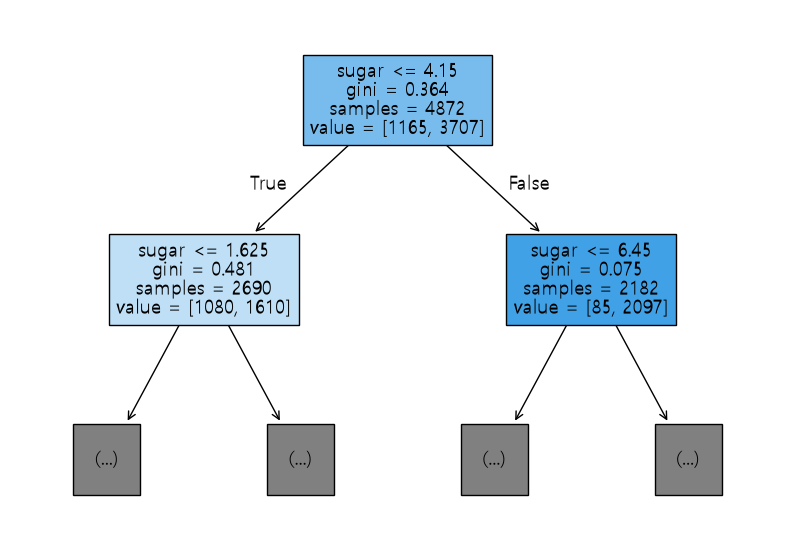

In [34]:
plt.figure(figsize=(10,7))
plot_tree(dt,max_depth=1,filled=True,\
          feature_names=['alcohol','sugar','pH'])
plt.show()

In [35]:
# 어떤 요인이 분류에 가장 큰 영향을 미쳤는 지 확인
print(dt.feature_importances_)

[0.23367672 0.52013306 0.24619022]


In [36]:
print('train:',dt.score(train_data,train_label))
print('test:',dt.score(test_data,test_label))

train: 0.9973316912972086
test: 0.8516923076923076


In [37]:
# 2.위의 자료를 훈련, 검증, 테스트데이터로 구분해서 분류

In [38]:
df = pd.read_csv('../data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [39]:
data = df[df.columns[:3]].values
data[:2]
label = df['class'].values
label[:2]

array([0., 0.])

In [40]:
# 데이터분리 : 훈련, 테스트로 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

In [41]:
# 훈련데이터로 훈련, 검증데이터로 나누기 => 전체는 훈련, 검증, 테스트데이터로 구성
sub_data,sub2_data,sub_label,sub2_label = \
train_test_split(train_data,train_label,test_size=0.2,random_state=42)

In [42]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(sub_data,sub_label)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [43]:
print('train:',dt.score(sub_data,sub_label))
print('검증:',dt.score(sub2_data,sub2_label))

train: 0.9971133028626413
검증: 0.864423076923077


In [44]:
# 3.모형의 평균 정확도를 구할 것

In [45]:
df = pd.read_csv('../data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [46]:
data = df[df.columns[:3]].values
label = df['class'].values

In [47]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [48]:
dt = DecisionTreeClassifier(max_depth=2, random_state=42)
score = cross_validate(dt,train_data,train_label,cv=5,return_train_score=True)
score

{'fit_time': array([0.00323868, 0.00196481, 0.00239229, 0.00191212, 0.00244617]),
 'score_time': array([0.00094604, 0.00081635, 0.00088835, 0.0009377 , 0.00079799]),
 'test_score': array([0.79076923, 0.82051282, 0.81724846, 0.8275154 , 0.81314168]),
 'train_score': array([0.82037465, 0.81498589, 0.80374551, 0.83119548, 0.81477681])}

In [49]:
print('train:',np.mean(score['train_score']))
print('test:',np.mean(score['test_score']))

train: 0.8170156675491915
test: 0.813837519085979


In [50]:
# 좀 더 정밀한 정확도 측정

In [51]:
dt = DecisionTreeClassifier(max_depth=3, random_state=42)

In [55]:
splitter = StratifiedKFold(n_splits=10,shuffle=True,random_state=42)
score = cross_validate(dt,train_data,train_label,cv=splitter, return_train_score=True)
score

{'fit_time': array([0.00436091, 0.00328398, 0.00478792, 0.0041914 , 0.00417161,
        0.00435305, 0.00425196, 0.00425792, 0.00468659, 0.00315619]),
 'score_time': array([0.00137997, 0.00110626, 0.00150084, 0.00139427, 0.00174356,
        0.00153399, 0.00213003, 0.00122285, 0.00214386, 0.00089979]),
 'test_score': array([0.87295082, 0.81147541, 0.85831622, 0.8275154 , 0.87268994,
        0.85831622, 0.85626283, 0.81314168, 0.83983573, 0.82546201]),
 'train_score': array([0.84375   , 0.84169708, 0.85267959, 0.85245154, 0.84834664,
        0.84971494, 0.84925884, 0.85153934, 0.85108324, 0.84903079])}

In [56]:
print('평균 정확도:', np.mean(score['test_score']))

평균 정확도: 0.8435966270575959
